# Tuning the scoring chain with Optuna

**The question.** The score (`outline_variability`) and the stabilizer before it hard-code about sixteen constants: how dark a pixel must be to be the body, how far the body mask is grown, where the ray edge sits, how wide the outline band is, how many rays, how far they reach, which interpolation, how wide the plate rim, … Each was set by hand. Which values separate the recordings labelled moving from those labelled still best?

**The search.** `scripts/pipeline_optuna.py` copies the chain with every constant as a parameter; at the app's values the copy gives the app's scores exactly (`check`: largest difference 0 over all 819 pairs, shifts identical). Nothing in the app was changed. Two objectives, both maximised, each the mean over four datasets (with a threshold per dataset, as their recordings differ in length):

- **F0.5**: the best F0.5 of the calls moving, at the threshold the calibration report would suggest.
- **separation**: d′ of log10(score), the distance between the mean moving and the mean still recording in units of their pooled standard deviation. F0.5 only sees the recordings near the threshold and saturates at 1 when they separate; d′ sees how far apart the two distributions are, i.e. how much room the threshold has.

Multi-objective TPE (Optuna 5, 8 worker processes sharing one journal). The first two trials are the app now (body mask and ray edge both at 0.3 of the darkest) and the committed code before 27 October 2026 (ray edge at 0.5).

**The data.** Every labelled (mite, recording) of the poke run (`poke_test_oct`, 90 frames, 304 labels) and of the three 30-frame datasets (`ground_truth_60min`, `ground_truth_90min`, `sample_data`, 515 labels): 819 in all. The long run is left out: its labels are the detector's own calls (CLAUDE.md), so it would only reward the app's current values.

**Guarding against overfitting.** Each dataset's mites are split at random in two halves. A trial is scored on the **tune** half only; the **test** half (mites the search never saw) gets the threshold chosen on the tune half. With 14 to 30 mites per dataset, a setting that only fits the tune mites shows up as a drop on the test half.

**Caveat.** The search ran in the base Python (OpenCV 4.12; Optuna is not in `discobox_env`), the app in OpenCV 5. Scores differ slightly between OpenCV builds (CLAUDE.md), not systematically.

**In this run, "app now" is the app of the morning of 27 October 2026** (body mask and ray edge both at 0.3, trial 0; `pipeline_optuna.EDGE_03`). The constants of trial 228 have been the app's since (the decision at the end).

In [1]:
import os, sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ.setdefault("DISCOBOX_CONFIG", str(ROOT / "config.default.yaml"))
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))
warnings.filterwarnings("ignore", category=Warning, module="optuna")

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd

import pipeline_optuna as po
from classes.ground_truth import calibration

%matplotlib inline
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=UserWarning)

study = optuna.load_study(study_name=po.STUDY, storage=po.storage())
trials = study.trials_dataframe(attrs=("number", "values", "params", "user_attrs", "state"))
trials = trials[trials["state"] == "COMPLETE"].rename(columns={"values_0": "f05", "values_1": "separation"})
trials.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in trials.columns]
trials = trials.set_index("number")
PARAMS = list(po.APP)
DATASETS = list(po.DATASETS)
pareto = {t.number for t in study.best_trials}
print(f"{len(trials)} trials, {len(pareto)} on the Pareto front")

600 trials, 1 on the Pareto front


## 1. The search space and the app's values

In [2]:
space = pd.DataFrame({
    "app now": pd.Series(po.APP),
    "before 27 Oct": pd.Series(po.BEFORE),
    "searched": pd.Series({name: str(dist).split("(")[0].replace("Distribution", "") + " " +
                           (str(dist.choices) if hasattr(dist, "choices") else f"{dist.low} to {dist.high}")
                           for name, dist in study.trials[0].distributions.items()}),
})
space["what it is"] = pd.Series({
    "stab_pad": "stabilizer: px round the box its centre is found in",
    "stab_rim": "stabilizer: rim width read for the plate's light (px)",
    "stab_share": "stabilizer: body = darker than this share of the darkest",
    "stab_grow": "stabilizer: body mask grown by this many px",
    "stab_interp": "stabilizer: interpolation of the cut",
    "rim": "score: rim width for the lamp and the noise floor (px)",
    "body_share": "score: body mask (for the centre) at this share of the darkest",
    "edge_share": "score: ray edge where darkness drops below this share",
    "grow": "score: body mask grown by this many px",
    "darkest_n": "both: 'the darkest' = mean of this many darkest pixels",
    "angles": "score: number of rays",
    "ray_step": "score: px between points on a ray",
    "reach": "score: ray length (px)",
    "width": "score: outline band, ± px round the edge",
    "ray_interp": "score: interpolation along the rays",
    "relative": "score: divided by the profile's mean to this power",
})
space

,app now,before 27 Oct,searched,what it is
stab_pad,8,8,Int 4 to 12,stabilizer: px round the box its centre is fou...
stab_rim,6,6,Int 3 to 8,stabilizer: rim width read for the plate's lig...
stab_share,0.3,0.3,Float 0.1 to 0.6,stabilizer: body = darker than this share of t...
stab_grow,2,2,Int 0 to 4,stabilizer: body mask grown by this many px
stab_interp,lanczos,lanczos,"Categorical ('lanczos', 'cubic', 'linear')",stabilizer: interpolation of the cut
rim,6,6,Int 3 to 8,score: rim width for the lamp and the noise fl...
body_share,0.3,0.3,Float 0.1 to 0.6,score: body mask (for the centre) at this shar...
edge_share,0.3,0.5,Float 0.15 to 0.7,score: ray edge where darkness drops below thi...
grow,2,2,Int 0 to 4,score: body mask grown by this many px
darkest_n,30,30,Int 5 to 80,both: 'the darkest' = mean of this many darkes...


## 2. The two objectives: every trial, and the Pareto front

Left, what the search optimised (the tune half). Right, the same trials on the test half. Red: the Pareto front (no other trial is better on both); the black cross is the app now, the black plus the code before 27 October.

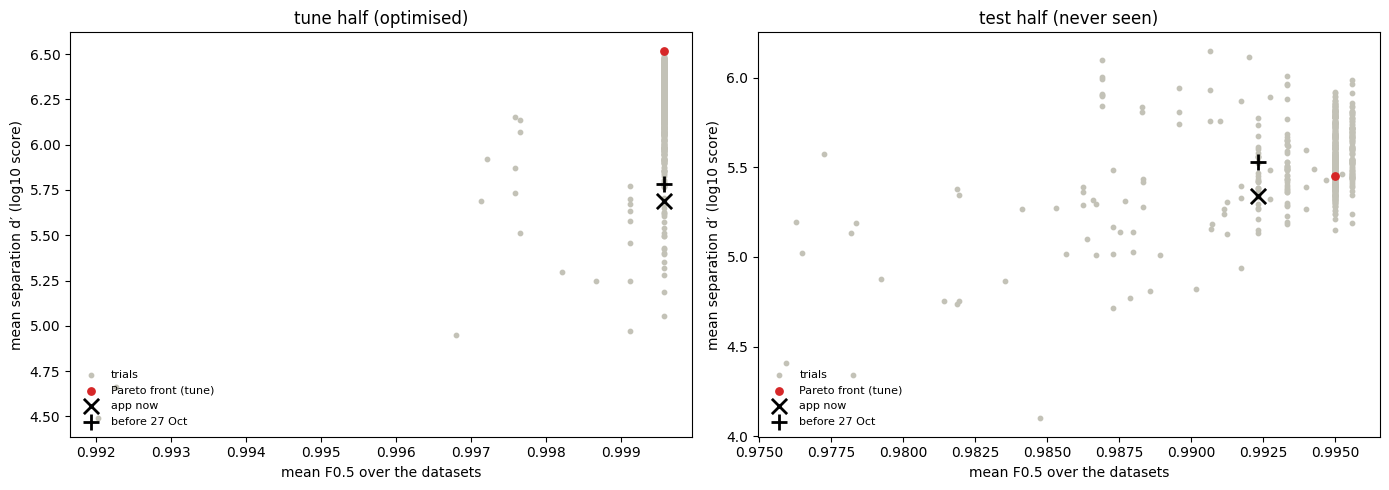

In [3]:
APP_T, BEFORE_T = 0, 1   # the two enqueued trials
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (fx, fy, title) in zip(axes, (("f05", "separation", "tune half (optimised)"),
                                       ("test_f05", "test_separation", "test half (never seen)"))):
    rest = trials.loc[~trials.index.isin(pareto)]
    front = trials.loc[trials.index.isin(pareto)]
    ax.scatter(rest[fx], rest[fy], s=10, color="#c3c2b7", label="trials")
    ax.scatter(front[fx], front[fy], s=28, color="#d62728", label="Pareto front (tune)")
    for number, marker, name in ((APP_T, "x", "app now"), (BEFORE_T, "+", "before 27 Oct")):
        ax.scatter(trials.loc[number, fx], trials.loc[number, fy], s=120, marker=marker, color="black", lw=2, label=name)
    ax.set(xlabel="mean F0.5 over the datasets", ylabel="mean separation d′ (log10 score)", title=title)
    ax.legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()

## 3. Does the tune half predict the test half?

If the search learnt something general, a trial's separation on the tune mites predicts its separation on the test mites. If it only fitted the tune mites, the best tune trials are not the best test trials.

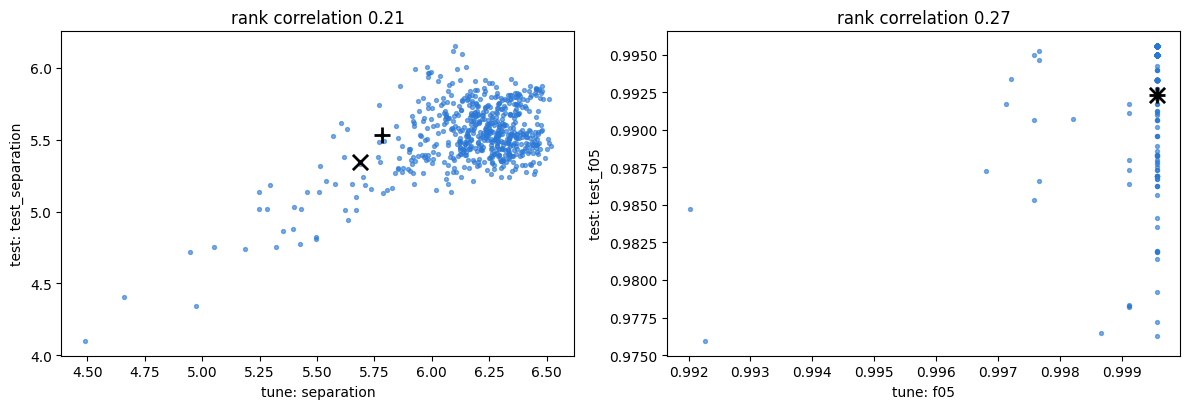

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (a, b) in zip(axes, (("separation", "test_separation"), ("f05", "test_f05"))):
    ax.scatter(trials[a], trials[b], s=8, color="#2a78d6", alpha=0.6)
    for number, marker in ((APP_T, "x"), (BEFORE_T, "+")):
        ax.scatter(trials.loc[number, a], trials.loc[number, b], s=120, marker=marker, color="black", lw=2)
    r = trials[[a, b]].corr(method="spearman").iloc[0, 1]
    ax.set(xlabel=f"tune: {a}", ylabel=f"test: {b}", title=f"rank correlation {r:.2f}")
plt.tight_layout()

## 4. Which parameters matter?

Optuna's importance (PED-ANOVA): how much each parameter's values differ between the best trials and the rest, normalised to sum to 1 per objective. F0.5 is nearly the same (≈ 1) in most trials, so its importances say little.

In [5]:
importance = pd.DataFrame({
    # PED-ANOVA (Optuna's default) explains *low* target values: the objectives are negated
    name: optuna.importance.get_param_importances(study, target=lambda t, i=i: -t.values[i])
    for i, name in enumerate(("f05", "separation"))
}).fillna(0).sort_values("separation", ascending=False)
importance

,f05,separation
edge_share,0.042,0.298
reach,0.061,0.176
body_share,0.106,0.170
relative,0.057,0.065
stab_pad,0.073,0.046
width,0.194,0.041
rim,0.041,0.039
stab_share,0.053,0.039
stab_grow,0.067,0.035
stab_rim,0.088,0.033


## 5. Each parameter against the separation

Every trial, its tune separation against each parameter's value. A clear trend or optimum means the parameter matters and the plot shows where to set it; a flat cloud means it doesn't. The dashed line is the app's value.

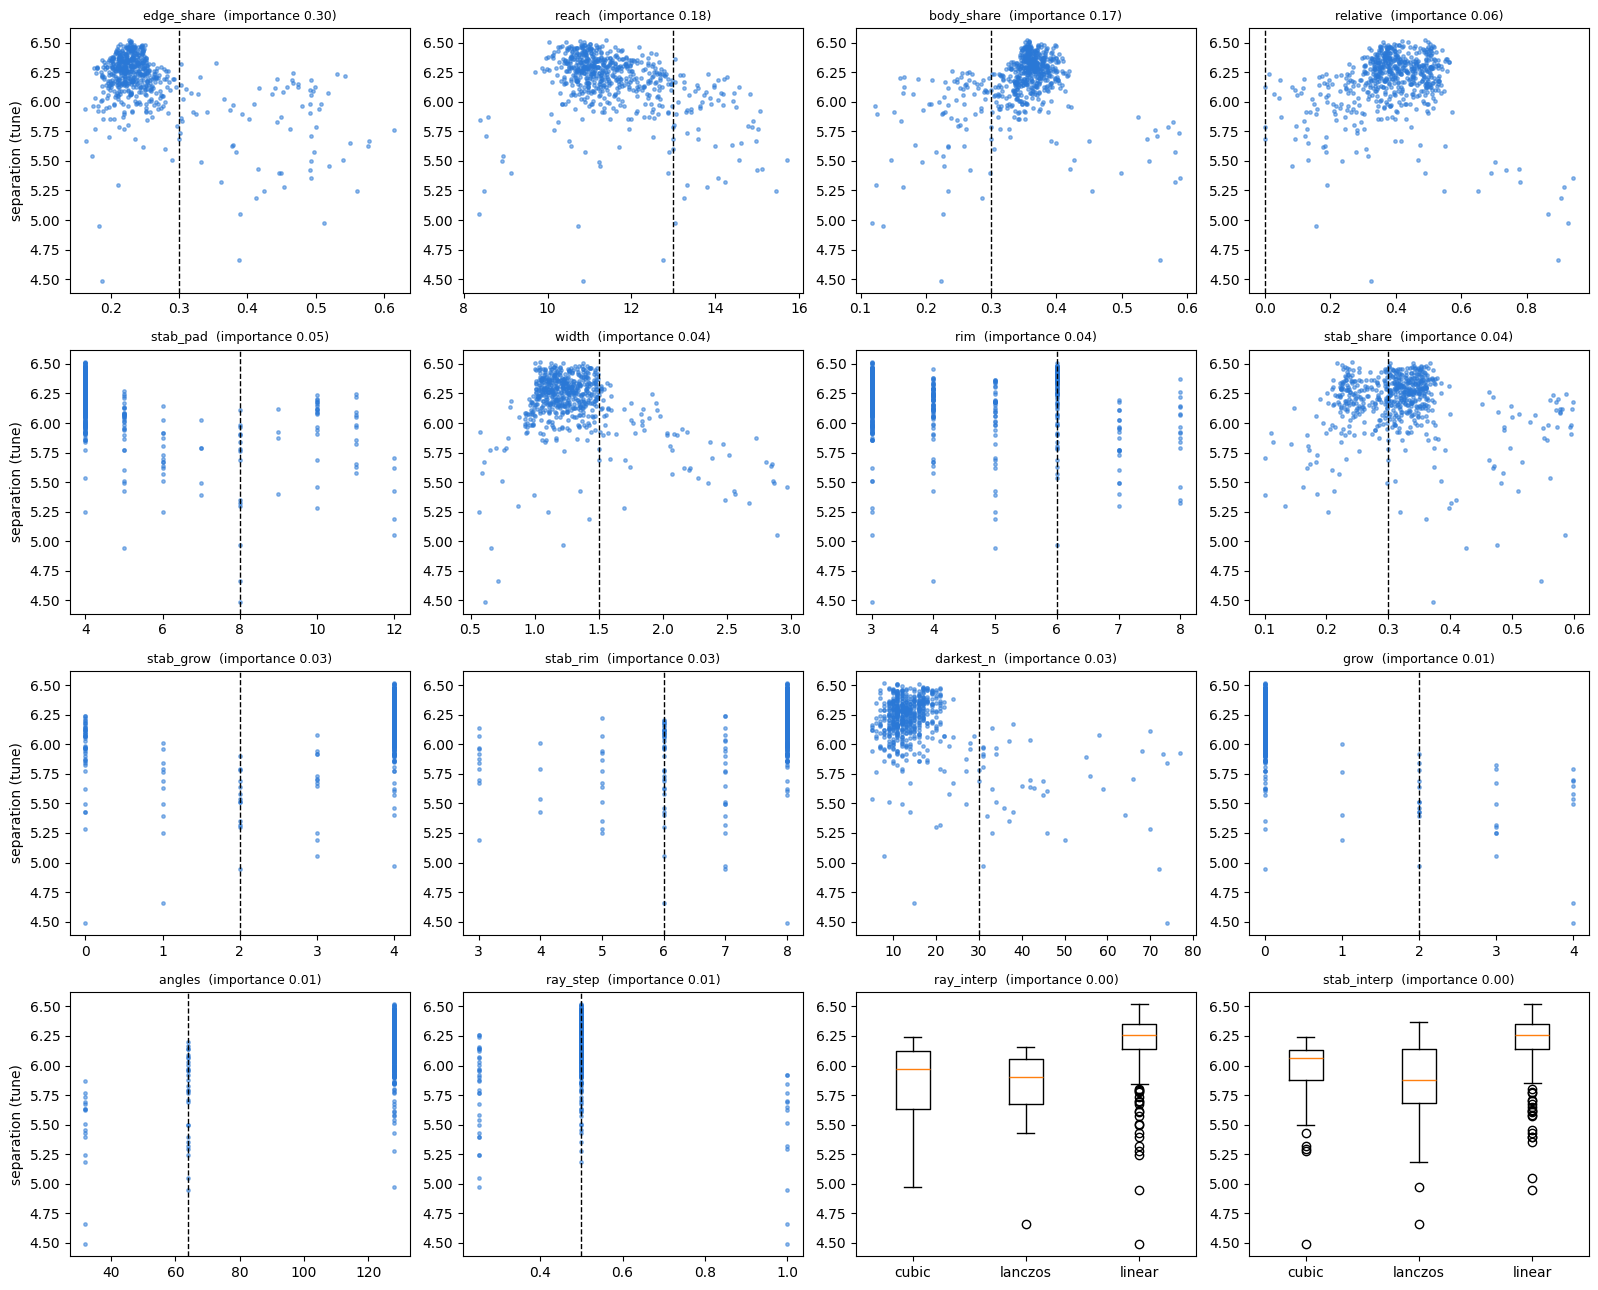

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, name in zip(axes.ravel(), importance.index.tolist() + [p for p in PARAMS if p not in importance.index]):
    values = trials[name]
    if values.dtype == object:
        groups = sorted(values.unique(), key=str)
        ax.boxplot([trials.loc[values == g, "separation"] for g in groups], tick_labels=[str(g) for g in groups])
    else:
        ax.scatter(values, trials["separation"], s=6, alpha=0.5, color="#2a78d6")
        ax.axvline(po.APP[name], color="black", ls="--", lw=1)
    ax.set_title(f"{name}  (importance {importance['separation'].get(name, 0):.2f})", fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("separation (tune)")
plt.tight_layout()

## 6. The app, the old code and the best trials, dataset by dataset

The Pareto trials, plus the best trial by **test** separation (for reference only: choosing by the test half would use it up), against the app and the old code. Per dataset: F0.5 and d′ on the tune half, and on the test half (F0.5 there at the tune threshold).

In [7]:
def per_dataset(number):
    row = trials.loc[number]
    return {(name[:12], key): row.get(f"{name}|{key}") for name in DATASETS for key in ("f05", "separation", "test_f05", "test_separation")}

shown = [APP_T, BEFORE_T] + sorted(pareto - {APP_T, BEFORE_T}, key=lambda n: -trials.loc[n, "separation"])
best_test = trials["test_separation"].idxmax()
if best_test not in shown:
    shown.append(best_test)
label = lambda n: {APP_T: "app now", BEFORE_T: "before 27 Oct"}.get(n, f"trial {n}" + (" (best test)" if n == best_test else ""))
summary = pd.DataFrame({label(n): {"F0.5 tune": trials.loc[n, "f05"], "d′ tune": trials.loc[n, "separation"],
                                   "F0.5 test": trials.loc[n, "test_f05"], "d′ test": trials.loc[n, "test_separation"]}
                        for n in shown}).T
summary

,F0.5 tune,d′ tune,F0.5 test,d′ test
app now,1.0,5.688,0.992,5.342
before 27 Oct,1.0,5.783,0.992,5.529
trial 228,1.0,6.519,0.995,5.454
trial 306 (best test),1.0,6.103,0.991,6.150


In [8]:
pd.DataFrame({label(n): per_dataset(n) for n in shown}).T

poke_test_oc                                     ground_truth                                     sample_data                                    
                               f05 separation test_f05 test_separation          f05 separation test_f05 test_separation         f05 separation test_f05 test_separation
app now                      0.998      4.640    0.989           4.733          1.0      6.075    1.000           4.838         1.0      4.840    0.996           6.804
before 27 Oct                0.998      4.820    0.989           4.867          1.0      6.357    1.000           4.945         1.0      4.922    0.996           7.113
trial 228                    0.998      5.173    0.995           4.623          1.0      7.190    1.000           5.171         1.0      5.492    1.000           6.665
trial 306 (best test)        0.998      5.108    0.989           5.122          1.0      6.185    0.989           5.975         1.0      5.479    1.000           7.510

In [9]:
params = pd.DataFrame({label(n): {p: trials.loc[n, p] for p in PARAMS} for n in shown}).T
params

,stab_pad,stab_rim,stab_share,stab_grow,stab_interp,rim,body_share,edge_share,grow,darkest_n,angles,ray_step,reach,width,ray_interp,relative
app now,8,6,0.3,2,lanczos,6,0.3,0.3,2,30,64,0.5,13.0,1.5,linear,0.0
before 27 Oct,8,6,0.3,2,lanczos,6,0.3,0.5,2,30,64,0.5,13.0,1.5,linear,0.0
trial 228,4,8,0.241,4,linear,3,0.355,0.226,0,8,128,0.5,11.396,1.039,linear,0.491
trial 306 (best test),4,8,0.258,4,linear,3,0.381,0.225,0,11,128,0.5,12.049,0.988,linear,0.528


## 7. The choice

A rule fixed before looking at the test half: among the trials whose tune F0.5 is within 0.005 of the best, the one with the largest tune separation. Then its test numbers against the app's.

In [10]:
good = trials[trials["f05"] >= trials["f05"].max() - 0.005]
choice = good["separation"].idxmax()
compare = summary.loc[[label(APP_T), label(BEFORE_T)]].copy()
compare.loc[f"trial {choice} (chosen)"] = [trials.loc[choice, k] for k in ("f05", "separation", "test_f05", "test_separation")]
display(compare)
changed = {p: (po.APP[p], trials.loc[choice, p]) for p in PARAMS if str(po.APP[p]) != str(trials.loc[choice, p])
           and not (isinstance(po.APP[p], float) and abs(float(po.APP[p]) - float(trials.loc[choice, p])) < 1e-9)}
pd.DataFrame(changed, index=["app", "chosen"]).T

,F0.5 tune,d′ tune,F0.5 test,d′ test
app now,1.0,5.688,0.992,5.342
before 27 Oct,1.0,5.783,0.992,5.529
trial 228 (chosen),1.0,6.519,0.995,5.454


,app,chosen
stab_pad,8,4
stab_rim,6,8
stab_share,0.3,0.241
stab_grow,2,4
stab_interp,lanczos,linear
rim,6,3
body_share,0.3,0.355
edge_share,0.3,0.226
grow,2,0
darkest_n,30,8


## 8. The score distributions, app against the chosen trial

From `results/scripts/pipeline_optuna_scores.csv.gz` (`export`: every pair scored with the app's values, the old code's and every Pareto trial's). Per dataset, the moving (green) and still (orange) recordings of both halves, log scale; the dashed line is each setting's F0.5 threshold on the tune half.

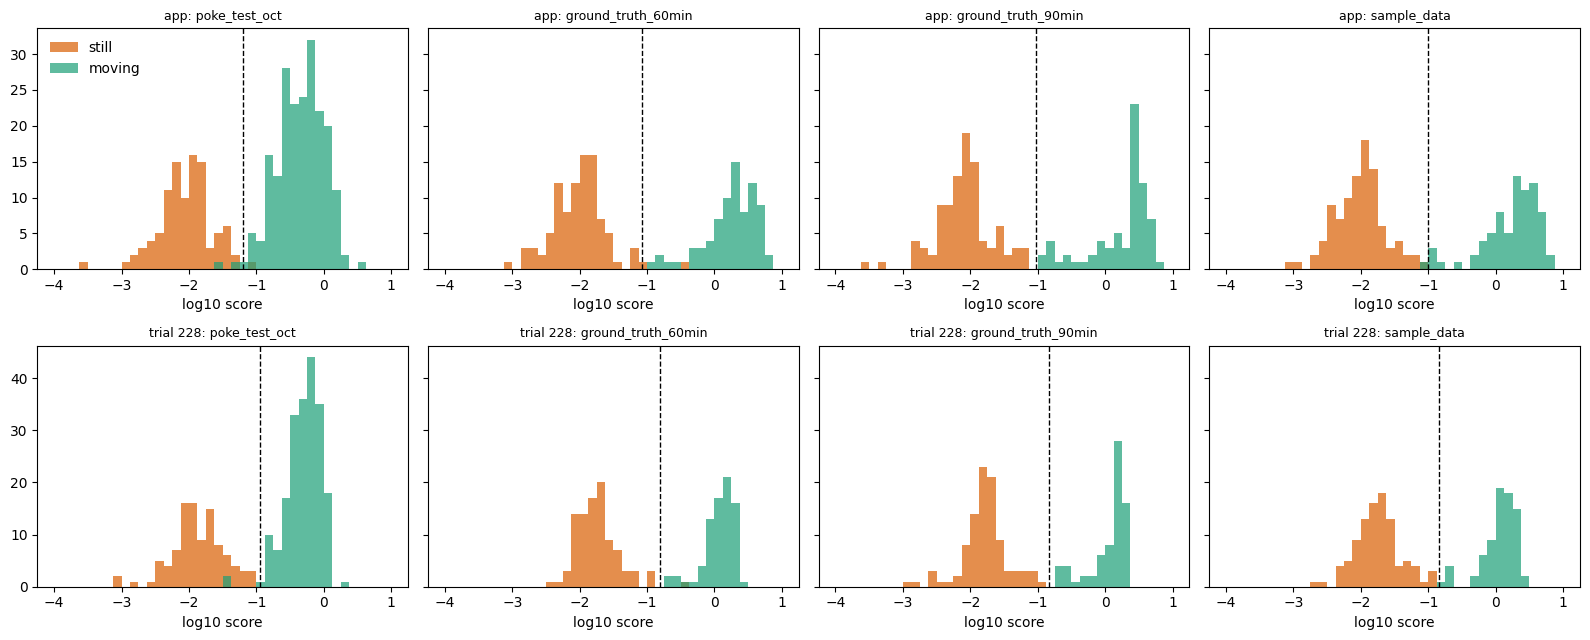

In [11]:
scores = pd.read_csv(po.SCORES, dtype={"mite": str})
setting = f"trial {choice}"
if setting not in set(scores["setting"]):
    print(f"{setting} is not in the export (not on the Pareto front); showing the Pareto trial with the best tune separation")
    setting = max((s for s in scores["setting"].unique() if s.startswith("trial")),
                  key=lambda s: trials.loc[int(s.split()[1]), "separation"])
fig, axes = plt.subplots(2, len(DATASETS), figsize=(4 * len(DATASETS), 6.5), sharey="row")
for row, name in zip(axes, ("app", setting)):
    for ax, dataset in zip(row, DATASETS):
        part = scores[(scores["setting"] == name) & (scores["dataset"] == dataset)]
        log = np.log10(part["score"].clip(lower=1e-4))
        bins = np.linspace(-4, 1, 41)
        ax.hist(log[~part["moving"]], bins=bins, color="#d95f02", alpha=0.7, label="still")
        ax.hist(log[part["moving"]], bins=bins, color="#1b9e77", alpha=0.7, label="moving")
        tune = part[part["fold"] == "tune"]
        threshold = calibration.best_f05_threshold(tune["score"].to_numpy(), tune["moving"].to_numpy())
        ax.axvline(np.log10(threshold), color="black", ls="--", lw=1)
        ax.set_title(f"{name}: {dataset[:18]}", fontsize=9)
        ax.set_xlabel("log10 score")
axes[0, 0].legend(frameon=False)
plt.tight_layout()

## 9. What it says

**F0.5 can't steer the search: it is at its ceiling.** On the tune half nearly every reasonable trial reaches F0.5 = 0.9996 (the app too); the few recordings that keep it below 1 are the same whatever the constants. All the steering came from the separation, which is why the Pareto front is a single trial.

**On the tune half the search found a lot; on the test half almost none of it holds.** The best trial raises the tune separation from 5.69 (app now) to 6.52, +15 %. On the mites it never saw: 5.45, against 5.34 for the app now and **5.53 for the code before 27 October**. Over the 50 best trials by tune separation the test separation has a median of 5.51 (quartiles 5.45–5.78): better than the app now in 90 % of them, better than the old code in only 48 %, a coin toss. Tune and test separation correlate with a rank correlation of only 0.21 (section 3). With 14 to 30 mites per dataset, 16 constants can be fitted to the tune mites; what they learn doesn't carry over. F0.5 on the test half rises from 0.992 to 0.995, about one recording.

**On the poke run, the one recorded as live runs now record, nothing beats the old code.** Test separation: app now 4.73, old code 4.87, median of the 50 best trials 4.75.

**The one result that holds: the ray edge at 0.5 beats 0.3.** The two enqueued trials differ only in the edge (0.3, as in the app since today, against 0.5 before). The 0.5 edge separates better on the tune half (5.78 against 5.69) and on the test half of all four datasets (poke run 4.87 against 4.73, 60 min 5.19 / 4.99, 90 min 4.95 / 4.84, sample_data 7.11 / 6.80), with the same F0.5. Moving the edge outwards lets the outline band reach a neighbour's blurred edge (the unit test of a neighbour beside the mite scores 5 times higher at 0.3), and that costs more than the legs it gains. The search's own trend (section 5) pulls the edge the other way, to about 0.23, but only on the tune mites.

**What the trends in section 5 do show** (for a later search on more labels): the separation depends mostly on the edge share, the ray reach and the body share; the number of rays, the step along them and both interpolations barely matter (importances ≤ 0.01; the box plots of the interpolations are not a fair comparison, as TPE sampled the favoured choice in its good region far more often). `relative` around 0.4 helps on the tune half, but it takes the score out of multiples of the noise floor.

**Recommendation.**
1. Put the ray edge back at 0.5 and keep the body mask at 0.3 (the code before 27 October): that is the only change the held-out mites support.
2. Don't adopt the tuned constants. The gain is within what 16 parameters fit to 14–30 mites by chance.
3. Tune again once there is a larger ground-truth run at 3 s / 30 fps (more mites, dead ones among them), with the same tune/test split by mite. This notebook and `scripts/pipeline_optuna.py` rerun it as they stand (`build`, `run`, `export`).

**Decision (27 October 2026).** The user chose to adopt trial 228, rounded to three decimals (`pipeline_optuna.APP`, now the app's constants; the app equals the search's copy at them, `check`). The default threshold is the poke run's F0.5 threshold on the new scale, 0.106.